# Determining parameter impact in systems biology models via sensitivity analysis: a comparative approach

__Kelsey I. Gasior__, Department of Applied and Computational Mathematics and Statistics, University of Notre Dame, Notre Dame, IN, USA

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

This notebook studies the two-equation E-cadherin / Slug model of the epithelial-mesenchymal transition (EMT) used by Gasior [[1]](https://doi.org/10.1038/s41540-026-00757-5) as a test case for global sensitivity analysis. It runs in Python 3 with numpy, scipy and matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later, and runs in well under two minutes (most of it the Sobol' index computations in the comparison section; the last cell prints the run time).

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import emt_model as em

warnings.filterwarnings('ignore', category=ac.ActiveSubspacesWarning)
SEED = 575                        # the only seed in this notebook (generate_data.py uses 575 and 576)
t_start = time.perf_counter()
C, T = 2, em.T_ON                 # the treatment group of this data set
TEX = [r'$\alpha_1$', r'$\alpha_2$', r'$\beta_1$', r'$\beta_2$', r'$k_0$', r'$k_1$', r'$k_2$',
       r'$IC_S$', r'$IC_E$', r'$IC_T$', r'$IC_C$']
qlabels = ['E-cadherin E (ng/mL)', 'Slug S (ng/mL)']

### Summary

Gasior [[1]](https://doi.org/10.1038/s41540-026-00757-5) compares Morris screening, partial rank correlation and Sobol' indices on a two-equation model of E-cadherin and Slug in the epithelial-mesenchymal transition, with 11 rate and half-saturation constants varied by $\pm10\%$ and $\pm25\%$ in eight treatment groups. We reimplement the model in Python with exact implicit-function gradients for one group, $C = 2$ cells with TGF-$\beta$ on, where every stored draw is monostable so both outputs are smooth along the sample, and reproduce the paper's subset Sobol' indices for that group (Figs. 2F–5F) to within the precision of reading its bars. On the $\pm10\%$ box E-cadherin and Slug at $t = 10{,}000$ min each have a one-dimensional active subspace ($\lambda_1/\lambda_2 = 227$ and 174.5; leave-one-out $R^2 = 0.99753$ and 0.99417 for a polynomial in the active variable), and the normalized activity scores agree with the all-input Sobol' total indices within 0.008.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ and is nearly constant along $\mathbf W_2^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a surrogate in $\mathbf y$ can replace $f$. We estimate $\mathbf C$ by the sample average of gradient outer products and assess it with the bootstrap. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015.

### The model

The model (Eqs. (1)–(2), p. 10 of [[1]](https://doi.org/10.1038/s41540-026-00757-5); first published in [[2]](https://doi.org/10.1016/j.jtbi.2022.111160)) tracks membrane-bound E-cadherin $E$ and the transcription factor Slug $S$ (both ng/mL) in a cell with $C$ neighbours exposed to exogenous TGF-$\beta$ at concentration $T$ (ng/mL):

$$
\frac{dE}{dt} = \frac{\alpha_1}{1 + (S/IC_S)^{n_1}} + k_0\,\frac{(C/IC_C)^{n_2}}{1 + (C/IC_C)^{n_2}} - \beta_1 E,
\qquad
\frac{dS}{dt} = \alpha_2 - k_1\,\frac{(E/IC_E)^{n_3}}{1 + (E/IC_E)^{n_3}} + k_2\,\frac{(T/IC_T)^{n_4}}{1 + (T/IC_T)^{n_4}} - \beta_2 S .
$$

(The printed equations lose their minus signs in the PDF's text layer; the page image has them, and the model text on p. 9 describes $-\beta_1E$, $-k_1(\cdot)$ and $-\beta_2S$ as losses.) The Hill coefficients $n_1, \dots, n_4 = 3, 4, 2, 3$ are fixed (Table 1, p. 9). The paper studies eight treatment groups, $C \in \{0, 1, 2, 6\}$ cells and $T \in \{0, 3.64\times10^{-6}\}$ ng/mL (pp. 10–11), and its quantities of interest are $E$ and $S$ at $t = 10{,}000$ min (p. 10), when the state has long settled ("Steady state values were quickly reached", Fig. 7 caption, p. 10).

**Inputs.** The 11 inputs are the rate constants and half-saturation constants of Table 1 (p. 9), each uniform (p. 11) on a box of $\pm10\%$ or $\pm25\%$ about its Table 1 value; the boxes are listed in Supplementary Table S1 (supplement p. 1), where the $\alpha_2$ and $k_1$ ranges are shifted (widths kept) "given monotonicity and negativity constraints". The code cell below prints them as the model module stores them.

**Initial conditions.** Supplementary Table S2 (supplement p. 1) gives $(E, S)(0)$ for each contact level, the same for both TGF-$\beta$ levels: epithelial (high $E$, low $S$) for $C \ge 1$ and mesenchymal for $C = 0$, as the Fig. 7 caption (p. 10) also says. They are the model's equilibria at the Table 1 values with $T = 0$.

**Treatment group and bistability.** This data set uses one group, $C = 2$ cells with TGF-$\beta$ on ($T = 3.64\times10^{-6}$ ng/mL); the choice is this data set's. The model is bistable for $C = 1, 2$ without TGF-$\beta$ (Fig. 7B, p. 10), and there a draw of the inputs can move the epithelial equilibrium away or leave it in place, so $E(10^4)$ jumps between two branches across the input box and is discontinuous. With TGF-$\beta$ on, the $C = 2$ cell is monostable at the Table 1 values (Fig. 7C: it switches to the mesenchymal state). The generator counts the equilibria at every draw by scanning the scalar equation left after setting $dE/dt = 0$; **all 4000 stored draws have exactly one equilibrium** (column `n_equilibria`), so no stored draw can switch branch and $E$, $S$ are smooth along the sample. The boxes themselves are not entirely monostable: near some of their corners a small bistable region exists, where a second, epithelial equilibrium appears and $E$ jumps (the cell after the data load counts the bistable corners, and the Sobol' section counts the bistable draws among its evaluations). `check_accuracy.py` repeats the count on a finer scan and confirms that a trajectory started from the mesenchymal initial condition ends at the same state; it also tabulates, for the other seven groups, how many draws are bistable (DATA.md).

**Quantities of interest and gradients.** $E$ and $S$ at $t = 10{,}000$ min, integrated with LSODA from the Table S2 initial condition and then polished to the equilibrium by Newton's method. Their gradients with respect to the 11 physical inputs come from the implicit function theorem at the equilibrium, $\partial\mathbf y/\partial\mathbf p = -J_y^{-1}J_p$, which equals the forward-sensitivity solution at $t = 10^4$ min because every stored draw relaxes at a rate of at least 0.356 per minute (the slowest Jacobian eigenvalue, printed by `generate_data.py`), so the transient at $t = 10^4$ min is far below rounding. The paper rounds $E$ and $S$ to $10^{-4}$ ng/mL (p. 10); the stored values are not rounded.

In [2]:
print(f"{'input':7s} {'units':12s} {'Table 1':>10s} {'+/-10 % box (Table S1)':>26s} {'+/-25 % box (Table S1)':>26s}  description")
for j, n in enumerate(em.NAMES):
    print(f'{n:7s} {em.UNITS[j]:12s} {em.NOMINAL[j]:10.4g} [{em.LOWER[10][j]:10.4g}, {em.UPPER[10][j]:10.4g}]  '
          f'[{em.LOWER[25][j]:10.4g}, {em.UPPER[25][j]:10.4g}]  {em.DESCRIPTIONS[j]}')
print(f'\nHill coefficients n1..n4 = {em.HILL}; T = {T:g} ng/mL, C = {C} cells; (E, S)(0) = {em.INITIAL[C]} ng/mL (Table S2)')
y0, info0 = em.qoi(em.NOMINAL, C, T, return_info=True)
print(f'at the Table 1 values: E(10^4) = {y0[0]:.6f}, S(10^4) = {y0[1]:.6f} ng/mL; equilibria: {info0["n_equilibria"]}; '
      f'Jacobian eigenvalues {np.array2string(info0["eig"].real, precision=4)} per min')
for TT in (0.0, T):
    eq = em.equilibria(em.NOMINAL, C, TT)
    print(f'equilibria (E, S) at the Table 1 values, C = {C}, T = {TT:g}: ' + '; '.join(f'({e:.5f}, {s:.5f})' for e, s in eq))

input   units           Table 1     +/-10 % box (Table S1)     +/-25 % box (Table S1)  description
alpha1  ng/(mL min)      0.1935 [    0.1742,     0.2129]  [    0.1452,     0.2419]  E-cadherin production
alpha2  ng/(mL min)        0.08 [    0.0772,     0.0932]  [    0.0772,     0.1172]  Slug production
beta1   1/min             6.035 [     5.431,      6.638]  [     4.526,      7.544]  E-cadherin degradation
beta2   1/min              0.83 [     0.747,      0.913]  [    0.6225,      1.038]  Slug degradation
k0      ng/(mL min)      0.1245 [     0.112,      0.137]  [    0.0938,     0.1556]  rate at which E-cadherin moves to the membrane due to contact
k1      ng/(mL min)        0.08 [    0.0669,     0.0829]  [    0.0429,     0.0829]  rate of Slug suppression by membrane-bound E-cadherin
k2      ng/(mL min)        0.04 [     0.036,      0.044]  [      0.03,       0.05]  rate of Slug upregulation by TGF-beta
ICS     ng/mL            0.0192 [    0.0173,     0.0211]  [    0.0144,      0.024

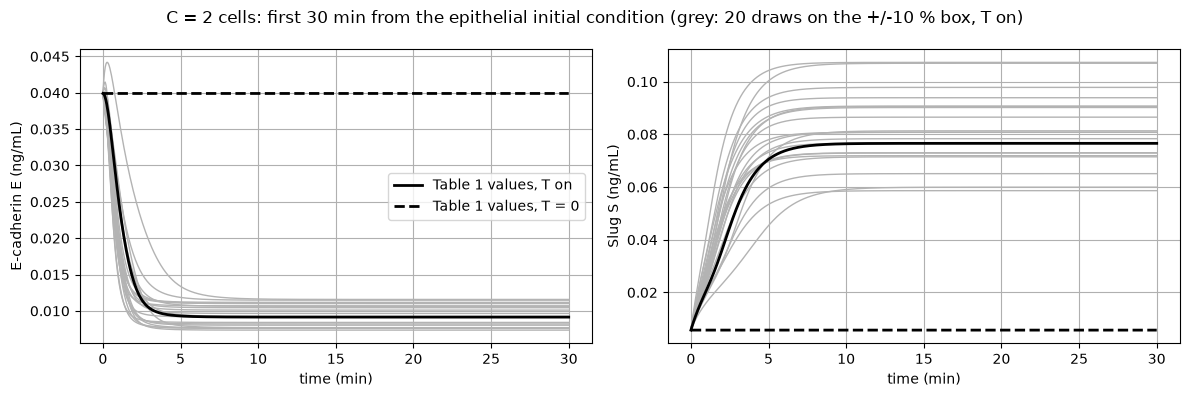

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
t = np.linspace(0, 30, 601)
rng = np.random.default_rng(SEED)
draws = em.LOWER[10] + (em.UPPER[10] - em.LOWER[10]) * rng.random((20, 11))
for x in draws:
    sol = em.trajectory(x, C, T, t_eval=t, t_end=t[-1])
    for q in range(2):
        axes[q].plot(t, sol.y[q], color='0.7', lw=1)
for TT, ls, lab in [(T, '-', 'Table 1 values, T on'), (0.0, '--', 'Table 1 values, T = 0')]:
    sol = em.trajectory(em.NOMINAL, C, TT, t_eval=t, t_end=t[-1])
    for q in range(2):
        axes[q].plot(t, sol.y[q], 'k', ls=ls, lw=2, label=lab)
for q in range(2):
    axes[q].set_xlabel('time (min)')
    axes[q].set_ylabel(qlabels[q])
    axes[q].grid(True)
axes[0].legend()
fig.suptitle('C = 2 cells: first 30 min from the epithelial initial condition (grey: 20 draws on the +/-10 % box, T on)')
fig.tight_layout()
plt.close(fig)
fig

From the epithelial initial condition of Table S2, the cell at the Table 1 values with TGF-$\beta$ on loses E-cadherin and gains Slug within about 15 minutes and settles at $E = 0.009144$, $S = 0.076590$ ng/mL; without TGF-$\beta$ (dashed) the initial condition is already an equilibrium. At the Table 1 values the group without TGF-$\beta$ has three equilibria (the bistable case, printed above), while with TGF-$\beta$ on it has one, with Jacobian eigenvalues $-6.13$ and $-0.735$ per minute. The 20 grey draws all settle well within the 30 minutes shown, so $t = 10{,}000$ min is far into the steady state.

### Load data

`generate_data.py` drew $M = 2000$ independent uniform (Monte Carlo) samples of the 11 inputs on each box (seeds 575 and 576) and wrote the physical inputs, $E$ and $S$ at $t = 10^4$ min with the number of equilibria at the draw, and the gradients with respect to the physical inputs (see `DATA.md` for the run time).

In [4]:
X, F, G = {}, {}, {}
for box in (10, 25):
    X[box] = np.loadtxt(f'inputs_pm{box}.csv', delimiter=',')                        # (M, 11) physical inputs
    F[box] = np.loadtxt(f'outputs_pm{box}.csv', delimiter=',')                       # (M, 3) E, S (ng/mL), n_equilibria
    G[box] = np.loadtxt(f'gradients_pm{box}.csv', delimiter=',').reshape(-1, 2, 11)  # (M, 2, 11) d(E, S)/dx
    print(f'+/-{box} %: inputs {X[box].shape}, outputs {F[box].shape}, gradients {G[box].shape}')

+/-10 %: inputs (2000, 11), outputs (2000, 3), gradients (2000, 2, 11)
+/-25 %: inputs (2000, 11), outputs (2000, 3), gradients (2000, 2, 11)


We check the files against the model at five draws of each box, the gradients there against central differences in the normalized inputs (step $10^{-6}$ of the half-width), and the equilibrium counts at all draws.

In [5]:
rows = [0, 1, 2, 3, 4]
h = 1e-6
for box in (10, 25):
    hw = (em.UPPER[box] - em.LOWER[box]) / 2
    f5 = em.qois(X[box][rows], C, T)
    err = []
    for i in rows:
        Gfd = np.column_stack([(em.qoi(X[box][i] + h * hw * e, C, T) - em.qoi(X[box][i] - h * hw * e, C, T)) / (2 * h)
                               for e in np.eye(11)])
        Gn = G[box][i] * hw
        err.append(np.linalg.norm(Gfd - Gn, axis=1) / np.linalg.norm(Gn, axis=1))
    inside = np.all((X[box] >= em.LOWER[box]) & (X[box] <= em.UPPER[box]))
    print(f'+/-{box} %: model vs files at rows {rows}: max relative difference {np.max(np.abs(f5 - F[box][rows, :2]) / F[box][rows, :2]):.1e}; '
          f'gradients vs central differences: max relative error E {np.max(err, axis=0)[0]:.1e}, S {np.max(err, axis=0)[1]:.1e}')
    print(f'   draws inside the box: {inside}; equilibria per draw: {sorted(set(F[box][:, 2].astype(int)))}; '
          f'E in [{F[box][:, 0].min():.5f}, {F[box][:, 0].max():.5f}], S in [{F[box][:, 1].min():.5f}, {F[box][:, 1].max():.5f}] ng/mL; '
          f'draws with S < 0: {(F[box][:, 1] < 0).sum()}')
# the boxes' 2^11 corners: equilibria counted by a vectorized scan of the scalar equation (4000 and 1000 points)
for box in (10, 25):
    bits = (np.arange(2 ** 11)[:, None] >> np.arange(10, -1, -1)) & 1          # corner patterns, alpha1 first
    corners = np.where(bits == 1, em.UPPER[box], em.LOWER[box])
    nc, nc1 = em.count_equilibria(corners, C, T), em.count_equilibria(corners, C, T, npts=1000)
    print(f'+/-{box} %: corners with 1 / 3 equilibria: {(nc == 1).sum()} / {(nc == 3).sum()} of {len(nc)} '
          f'(1000-point scan: {(nc1 == 1).sum()} / {(nc1 == 3).sum()})')
    if box == 25:
        k = int(np.nonzero(nc == 3)[0][0])
        eq = em.equilibria(corners[k], C, T)
        y = em.qoi(corners[k], C, T)
        print(f'   first bistable corner (' + ''.join('LU'[b] for b in bits[k]) + ', L/U = lower/upper end, alpha1 ... ICC): '
              f'equilibria E = {np.array2string(eq[:, 0], precision=4)} ng/mL; the trajectory from Table S2 ends at E = {y[0]:.4f}, S = {y[1]:.4f}')

+/-10 %: model vs files at rows [0, 1, 2, 3, 4]: max relative difference 0.0e+00; gradients vs central differences: max relative error E 1.5e-09, S 1.8e-09
   draws inside the box: True; equilibria per draw: [np.int64(1)]; E in [0.00604, 0.01454], S in [0.04726, 0.12140] ng/mL; draws with S < 0: 0


+/-25 %: model vs files at rows [0, 1, 2, 3, 4]: max relative difference 0.0e+00; gradients vs central differences: max relative error E 4.0e-10, S 5.3e-10
   draws inside the box: True; equilibria per draw: [np.int64(1)]; E in [0.00322, 0.02592], S in [0.02077, 0.20775] ng/mL; draws with S < 0: 0


+/-10 %: corners with 1 / 3 equilibria: 2045 / 3 of 2048 (1000-point scan: 2045 / 3)


+/-25 %: corners with 1 / 3 equilibria: 2023 / 25 of 2048 (1000-point scan: 2023 / 25)
   first bistable corner (LLLLLULULUU, L/U = lower/upper end, alpha1 ... ICC): equilibria E = [0.031  0.0179 0.0052] ng/mL; the trajectory from Table S2 ends at E = 0.0310, S = 0.0145


On both boxes the model reproduces the stored outputs at the five rows to below $10^{-15}$ relative (the same code path wrote the files; `check_accuracy.py` compares with tighter integrations), and the gradients agree with central differences to $1.8\times10^{-9}$ ($\pm10\%$) and $5.3\times10^{-10}$ ($\pm25\%$), the size of the differences' own truncation and rounding error. Every draw lies inside its box, every stored draw has exactly one equilibrium, and no draw has $S < 0$ (the paper shifted the $\alpha_2$ and $k_1$ ranges because some draws gave negative values; none occur in this group). On the $\pm10\%$ box $E$ ranges over $[0.00604, 0.01454]$ and $S$ over $[0.04726, 0.12140]$ ng/mL; on the $\pm25\%$ box over $[0.00322, 0.02592]$ and $[0.02077, 0.20775]$.

The boxes are not monostable everywhere. Of the $2^{11} = 2048$ corners, 3 are bistable on the $\pm10\%$ box and 25 on the $\pm25\%$ box (the coarser 1000-point scan finds the same). At the first bistable $\pm25\%$ corner the trajectory from the Table S2 initial condition stays on the epithelial branch, $E = 0.0310$ ng/mL, above the largest stored value 0.02592, so $E$ is discontinuous across the edge of this region. The region is small: the Sobol' section below counts it among more than 100,000 uniform draws per box. No stored draw falls in it, so the sample, the gradients and the subspaces below are unaffected.

### Estimate the subspace

The model is cheap and smooth on these boxes and the gradients are exact up to rounding, so we use the gradient-based estimator (`estimator="as"`), $\hat{\mathbf C} = \frac1M\sum_i \nabla f_i \nabla f_i^T$ in normalized coordinates, for $E$ and $S$ separately. The input space is `ac.Uniform` on the box; we pass the physical inputs and gradients, and the library maps each input to $[-1, 1]$ through its range (the normalized gradient is the physical gradient times the half-width). We use 500 bootstrap replicates and orient each eigenvector so that the output increases along it (`ac.orient(..., by="covariance")`; the paper has no eigenvector figures). The headline study is the $\pm10\%$ box; the $\pm25\%$ box follows in a shorter section.

In [6]:
spaces = {box: ac.Uniform(em.LOWER[box], em.UPPER[box], names=list(em.NAMES)) for box in (10, 25)}
subs = {}
for box in (10, 25):
    for q in range(2):
        sub = ac.active_subspace(space=spaces[box], X=X[box], f=F[box][:, q], grads=G[box][:, q], estimator='as',
                                 nboot=500, rng=SEED)
        subs[box, q] = ac.orient(sub, by='covariance', X=X[box], f=F[box][:, q], columns=3)
        lam = subs[box, q].eigenvalues
        b = subs[box, q].bootstrap_eigenvalues
        r12 = b[:, 0] / b[:, 1]
        print(f'+/-{box} % {em.QOI_NAMES[q]}: eigenvalues {np.array2string(lam[:4], precision=3)} ...; '
              f'ratios lambda_k/lambda_k+1 (k = 1..4) {np.array2string(lam[:4] / lam[1:5], precision=1)}; '
              f'lambda_1/lambda_2 over the replicates 2.5-97.5 % [{np.percentile(r12, 2.5):.1f}, {np.percentile(r12, 97.5):.1f}]; '
              f'gap rule n = {subs[box, q].n}; share of the trace left out by n = 1: {lam[1:].sum() / lam.sum():.4f}')

+/-10 % E: eigenvalues [6.781e-06 2.987e-08 4.265e-09 2.820e-09] ...; ratios lambda_k/lambda_k+1 (k = 1..4) [227.    7.    1.5  10.1]; lambda_1/lambda_2 over the replicates 2.5-97.5 % [172.6, 305.7]; gap rule n = 1; share of the trace left out by n = 1: 0.0055


+/-10 % S: eigenvalues [4.091e-04 2.345e-06 5.589e-07 1.597e-07] ...; ratios lambda_k/lambda_k+1 (k = 1..4) [174.5   4.2   3.5   1.5]; lambda_1/lambda_2 over the replicates 2.5-97.5 % [163.8, 184.8]; gap rule n = 1; share of the trace left out by n = 1: 0.0082


+/-25 % E: eigenvalues [4.502e-05 3.288e-06 2.633e-07 1.433e-07] ...; ratios lambda_k/lambda_k+1 (k = 1..4) [13.7 12.5  1.8  2.2]; lambda_1/lambda_2 over the replicates 2.5-97.5 % [6.3, 46.6]; gap rule n = 1; share of the trace left out by n = 1: 0.0774


+/-25 % S: eigenvalues [2.466e-03 7.415e-05 2.636e-05 6.916e-06] ...; ratios lambda_k/lambda_k+1 (k = 1..4) [33.3  2.8  3.8  1.9]; lambda_1/lambda_2 over the replicates 2.5-97.5 % [31.1, 35.6]; gap rule n = 1; share of the trace left out by n = 1: 0.0454


### Results ($\pm10\%$ box)

**Eigenvalues.** The figure shows the eigenvalues with 95 % bootstrap bands, $E$ left and $S$ right.

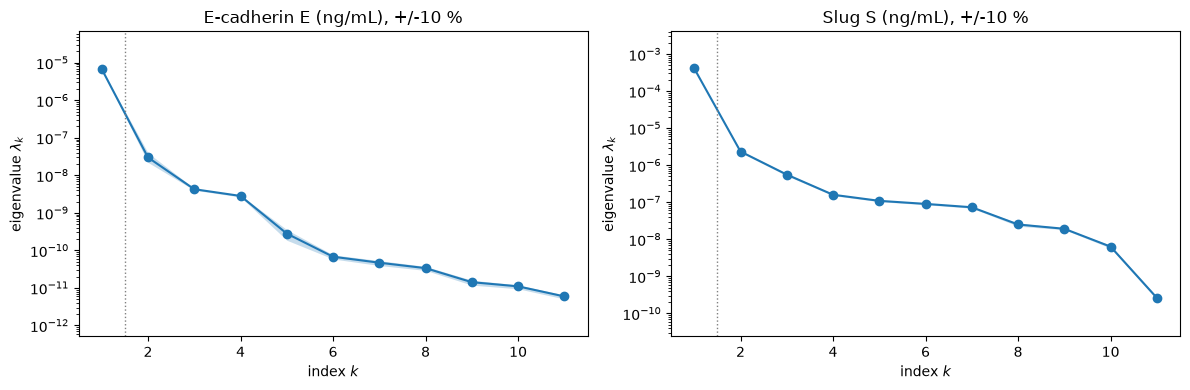

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for q in range(2):
    ac.plotting.plot_eigenvalues(subs[10, q], ax=axes[q])
    axes[q].set_title(qlabels[q] + ', +/-10 %')
fig.tight_layout()
plt.close(fig)
fig

On the $\pm10\%$ box the first eigenvalue dominates for both outputs. For $E$, $\lambda_1 = 6.781\times10^{-6}$ and $\lambda_1/\lambda_2 = 227$ (172.6–305.7 over the bootstrap replicates); for $S$, $\lambda_1 = 4.091\times10^{-4}$ and $\lambda_1/\lambda_2 = 174.5$ (163.8–184.8). The next ratios are much smaller, 7.0 ($E$) and 4.2 ($S$), and the eigenvalues left out by $n = 1$ hold 0.55 % ($E$) and 0.82 % ($S$) of the trace. We use $n = 1$ for both outputs (the library's gap rule gives the same); the subspace errors and the leave-one-out $R^2$ below support it.

E: bootstrap mean subspace distance, k = 1..4: [0.002 0.022 0.046 0.02 ]
S: bootstrap mean subspace distance, k = 1..4: [0.002 0.017 0.026 0.07 ]


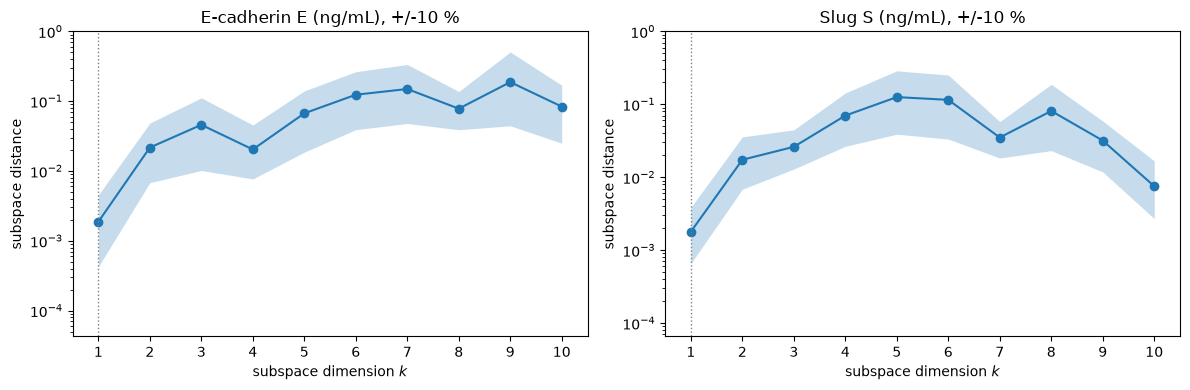

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for q in range(2):
    ac.plotting.plot_subspace_errors(subs[10, q], ax=axes[q])
    axes[q].set_title(qlabels[q] + ', +/-10 %')
    dist = subs[10, q].bootstrap_distances.mean(axis=0)
    print(f'{em.QOI_NAMES[q]}: bootstrap mean subspace distance, k = 1..4: {np.array2string(dist[:4], precision=3)}')
fig.tight_layout()
plt.close(fig)
fig

The bootstrap mean subspace distance of the one-dimensional subspace is 0.002 for both outputs, against 0.022 ($E$) and 0.017 ($S$) for two dimensions: $\mathbf w_1$ is well determined by 2000 draws, the second direction less so.

E: w1 = [ 0.017 -0.064 -0.389  0.051  0.367  0.032 -0.016  0.051 -0.03   0.023
 -0.838]
   w2 = [-0.119  0.611  0.215 -0.329  0.055 -0.395  0.147 -0.325  0.296 -0.213
 -0.198]
S: w1 = [-0.01   0.513  0.232 -0.46  -0.223 -0.233  0.129 -0.029  0.232 -0.191
  0.51 ]
   w2 = [ 0.047 -0.05  -0.233 -0.759  0.086  0.512  0.007  0.133 -0.237 -0.015
 -0.148]


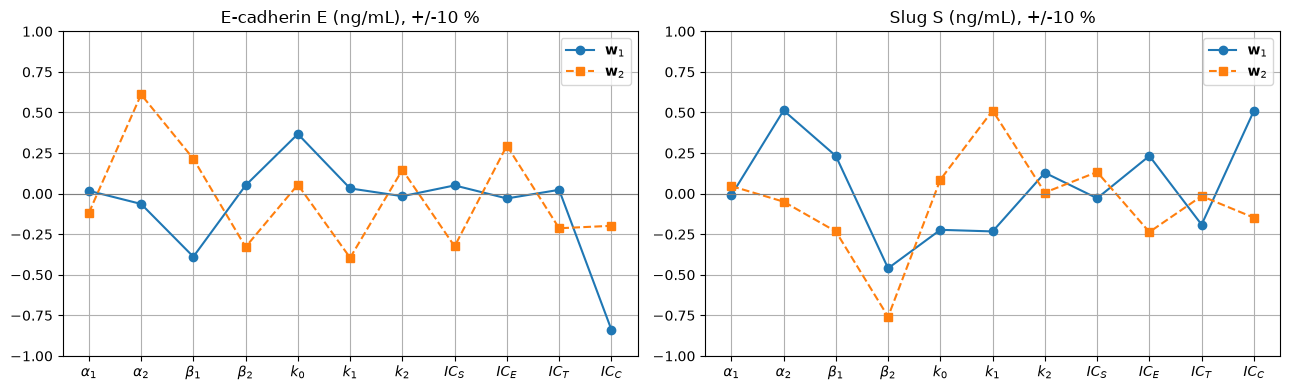

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for q in range(2):
    W = subs[10, q].W
    axes[q].plot(range(11), W[:, 0], 'o-', label=r'$\mathbf{w}_1$')
    axes[q].plot(range(11), W[:, 1], 's--', label=r'$\mathbf{w}_2$')
    axes[q].axhline(0, color='0.5', lw=0.8)
    axes[q].set_xticks(range(11))
    axes[q].set_xticklabels(TEX)
    axes[q].set_ylim(-1, 1)
    axes[q].grid(True)
    axes[q].legend()
    axes[q].set_title(qlabels[q] + ', +/-10 %')
    print(f'{em.QOI_NAMES[q]}: w1 = {np.array2string(W[:, 0], precision=3)}')
    print(f'{"":3s}w2 = {np.array2string(W[:, 1], precision=3)}')
fig.tight_layout()
plt.close(fig)
fig

E-cadherin increases along $\mathbf w_1 = (0.017, -0.064, -0.389, 0.051, 0.367, 0.032, -0.016, 0.051, -0.03, 0.023, -0.838)$: it falls with the half-maximal contact constant $IC_C$ (weight $-0.838$) and the E-cadherin degradation rate $\beta_1$ ($-0.389$) and rises with the membrane-translocation rate $k_0$ (0.367); the other eight weights are below 0.07 in magnitude. These are the three inputs of the paper's subset for this group (Fig. 2F). Slug increases along $\mathbf w_1 = (-0.01, 0.513, 0.232, -0.46, -0.223, -0.233, 0.129, -0.029, 0.232, -0.191, 0.51)$: it rises with Slug production $\alpha_2$ (0.513) and with $IC_C$ (0.51) and falls with Slug degradation $\beta_2$ ($-0.46$), with weights between 0.129 and 0.233 in magnitude on $\beta_1$, $k_0$, $k_1$, $k_2$, $IC_E$ and $IC_T$. A larger $IC_C$ means the two contacts draw less E-cadherin to the membrane, which in turn suppresses Slug less, so $IC_C$ moves the two outputs in opposite directions.

E: y1 = w1^T x in [-1.44, 1.48]; corr(y1, f) = 0.99386
S: y1 = w1^T x in [-1.86, 1.80]; corr(y1, f) = 0.99709


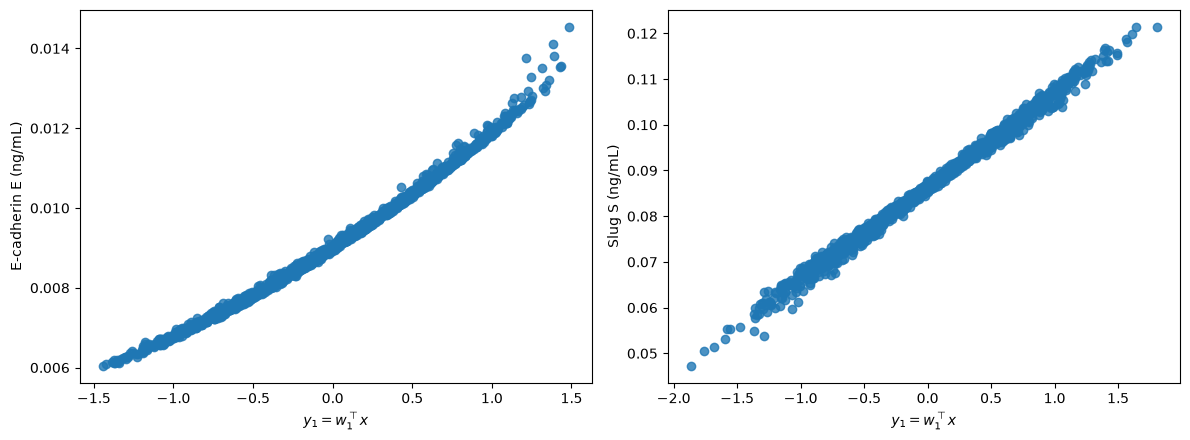

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for q in range(2):
    ac.plotting.plot_sufficient_summary(subs[10, q], X=X[10], f=F[10][:, q], dims=1, qoi_label=qlabels[q], ax=axes[q])
fig.tight_layout()
plt.close(fig)
XN = spaces[10].to_normalized(X[10])
for q in range(2):
    y = XN @ subs[10, q].W[:, 0]
    print(f'{em.QOI_NAMES[q]}: y1 = w1^T x in [{y.min():.2f}, {y.max():.2f}]; corr(y1, f) = {np.corrcoef(y, F[10][:, q])[0, 1]:.5f}')
fig

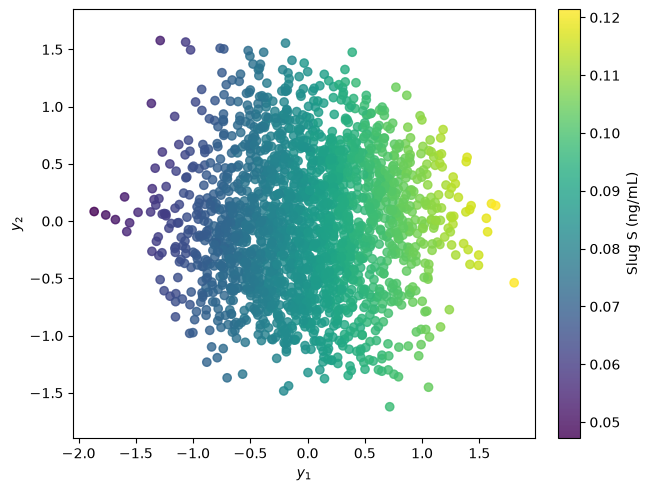

In [11]:
fig, ax = ac.plotting.plot_sufficient_summary(ac.with_dimension(subs[10, 1], 2), X=X[10], f=F[10][:, 1], dims=2,
                                              qoi_label=qlabels[1])
plt.close(fig)
fig

Both one-dimensional summary plots show a tight trend, convex for $E$ ($\mathrm{corr}(y_1, E) = 0.99386$) and nearly linear for $S$ (0.99709), with $y_1$ in $[-1.44, 1.48]$ and $[-1.86, 1.80]$. In the two-dimensional plot for $S$ the colour changes mainly along $y_1$ and only slightly along $y_2$, as $\lambda_2/\lambda_1 = 1/174.5$ says it should.

#### Surrogates on the active variables

We fit polynomials in the first active variable (degrees 1 and 2) and in the first two (degree 2) and report the leave-one-out $R^2$; a quadratic in all 11 normalized inputs is the reference.

+/-10 % E: linear, n = 1 0.98771, quadratic, n = 1 0.99753, quadratic, n = 2 0.99892, quadratic, all 11 0.99924
+/-10 % S: linear, n = 1 0.99417, quadratic, n = 1 0.99417, quadratic, n = 2 0.99890, quadratic, all 11 0.99983
+/-25 % E: linear, n = 1 0.93356, quadratic, n = 1 0.97759, quadratic, n = 2 0.98269, quadratic, all 11 0.98597
+/-25 % S: linear, n = 1 0.96691, quadratic, n = 1 0.97224, quadratic, n = 2 0.99137, quadratic, all 11 0.99706


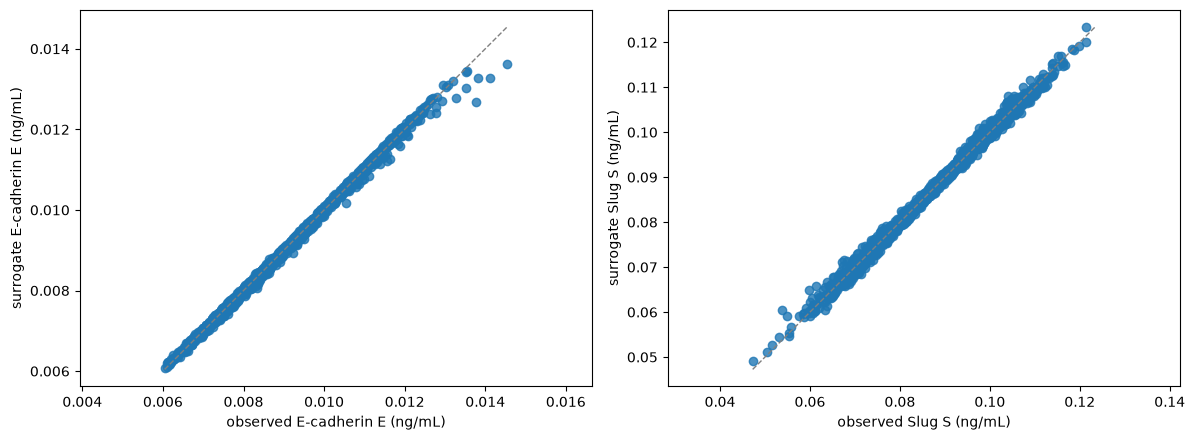

In [12]:
loo = {}
for box in (10, 25):
    for q in range(2):
        for name, k, deg in [('linear, n = 1', 1, 1), ('quadratic, n = 1', 1, 2), ('quadratic, n = 2', 2, 2)]:
            s = ac.fit_surrogate(X=X[box], f=F[box][:, q], subspace=ac.with_dimension(subs[box, q], k), kind='poly', degree=deg)
            loo[box, q, name] = s
        loo[box, q, 'quadratic, all 11'] = ac.fit_surrogate(X=X[box], f=F[box][:, q], space=spaces[box], subspace=None,
                                                            kind='poly', degree=2)
        print(f'+/-{box} % {em.QOI_NAMES[q]}: ' + ', '.join(f'{name} {loo[box, q, name].loo_r_squared:.5f}'
              for name in ('linear, n = 1', 'quadratic, n = 1', 'quadratic, n = 2', 'quadratic, all 11')))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for q in range(2):
    ac.plotting.plot_surrogate_fit(loo[10, q, 'quadratic, n = 1'], X=X[10], f=F[10][:, q], qoi_label=qlabels[q], ax=axes[q])
fig.tight_layout()
plt.close(fig)
fig

On the $\pm10\%$ box a quadratic in $y_1$ has leave-one-out $R^2 = 0.99753$ for $E$, and a line has 0.99417 for $S$ (a quadratic adds nothing for $S$: 0.99417). A quadratic in two active variables reaches 0.99892 and 0.99890, and a quadratic in all 11 inputs 0.99924 and 0.99983. One active variable therefore leaves about 0.25 % ($E$) and 0.58 % ($S$) of the variance unexplained, and a second would remove most of that for $S$; we keep $n = 1$, where the eigenvalue gap is clearest.

### Secondary study: the $\pm25\%$ box

The same estimator on the wider box (2000 further draws, seed 576). Every stored draw is still monostable (above), so the outputs are smooth along the sample; the wider box makes them more nonlinear, and the small bistable region near some of its corners is not sampled.

+/-25 % E: w1 = [ 0.019 -0.078 -0.438  0.048  0.376  0.056 -0.018  0.048 -0.026  0.025
 -0.807]; |w1(+/-25 %) . w1(+/-10 %)| = 0.9979; bootstrap mean subspace distance k = 1, 2: [0.016 0.083]
+/-25 % S: w1 = [-0.005  0.517  0.183 -0.618 -0.175 -0.233  0.132 -0.014  0.182 -0.191
  0.382]; |w1(+/-25 %) . w1(+/-10 %)| = 0.9756; bootstrap mean subspace distance k = 1, 2: [0.005 0.023]


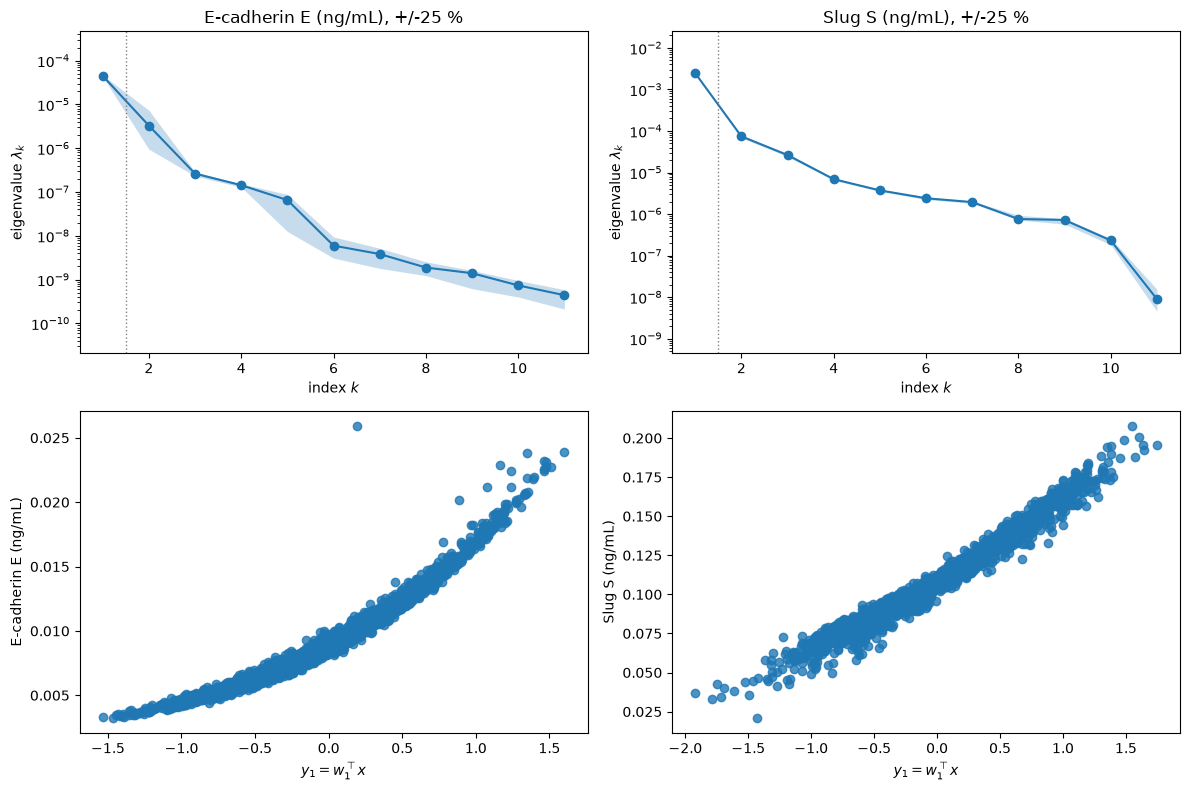

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for q in range(2):
    ac.plotting.plot_eigenvalues(subs[25, q], ax=axes[0, q])
    axes[0, q].set_title(qlabels[q] + ', +/-25 %')
    ac.plotting.plot_sufficient_summary(subs[25, q], X=X[25], f=F[25][:, q], dims=1, qoi_label=qlabels[q], ax=axes[1, q])
    W = subs[25, q].W
    print(f'+/-25 % {em.QOI_NAMES[q]}: w1 = {np.array2string(W[:, 0], precision=3)}; '
          f'|w1(+/-25 %) . w1(+/-10 %)| = {abs(W[:, 0] @ subs[10, q].W[:, 0]):.4f}; '
          f'bootstrap mean subspace distance k = 1, 2: {np.array2string(subs[25, q].bootstrap_distances.mean(axis=0)[:2], precision=3)}')
fig.tight_layout()
plt.close(fig)
fig

On the $\pm25\%$ box the gaps are smaller (eigenvalues and ratios printed in the estimation cell above). For $S$, $\lambda_1/\lambda_2 = 33.3$ (31.1–35.6 over the replicates), $n = 1$ leaves 4.54 % of the trace, and the leave-one-out $R^2$ is 0.97224 for a quadratic in $y_1$ and 0.99137 in $(y_1, y_2)$, so on this box two active variables describe Slug noticeably better. For $E$, $\lambda_1/\lambda_2 = 13.7$ with a wide bootstrap range (6.3–46.6), and the next ratio, $\lambda_2/\lambda_3 = 12.5$, is comparable, so a two-dimensional subspace is about as well separated as the one-dimensional one; $n = 1$ leaves 7.74 % of the trace. A quadratic in $y_1$ has $R^2 = 0.97759$, in $(y_1, y_2)$ 0.98269 and in all 11 inputs 0.98597, so the remaining error is mostly nonlinearity that no quadratic captures rather than a missing direction. We report $n = 1$ on this box too, with these caveats. The leading direction hardly turns between the boxes: $|\mathbf w_1^{\pm25}\cdot\mathbf w_1^{\pm10}| = 0.9979$ for $E$ and 0.9756 for $S$. The isolated point far above the $E$ trend is the largest value on this box, $E = 0.02592$ ng/mL, a draw where E-cadherin has moved most of the way back toward its epithelial level; it is still monostable (one equilibrium, like every stored draw), and DATA.md describes it.

### Comparison with the paper

The paper [[1]](https://doi.org/10.1038/s41540-026-00757-5) does not compute an active subspace. It reduces the 11 inputs of each treatment group to a subset of two to four with Morris screening (MMS) or with partial rank correlation (PRCC, $|\rho| \ge 0.5$, or the top three), and then computes first-order and total Sobol' indices $S_1$, $S_T$ of the subset only (Methods, pp. 10–11; the code is SALib [[5]](https://doi.org/10.21105/joss.00097) with Saltelli sampling). The paper does not say what values the inputs outside the subset take; this data set reads them as held at their Table 1 values, a reading that the close agreement with the bars below supports but that the paper does not state. Figs. 2–5 (pp. 3–6) show the bars; for $C = 2$ with TGF-$\beta$ on they are panels 2F, 3F ($E$, $\pm10\%$ and $\pm25\%$) and 4F, 5F ($S$), and the paper prints no numerical values, so the values below were **read from the bars by eye** (about $\pm0.01$).

We compute two sets of Sobol' indices with our model, using `emt_model.unique_equilibrium`, which matches the stored outputs at every stored draw (`check_accuracy.py`, check 4) but is valid only where the draw is monostable. We therefore count the equilibria at every evaluated row (`emt_model.count_equilibria`, 1000-point scan) and evaluate the few bistable rows by the trajectory from the Table S2 initial condition (`emt_model.qois`), as the stored data are. The indices use the Saltelli and Jansen estimators [[4]](https://doi.org/10.1016/j.cpc.2009.09.018) on independent uniform draws, with 95 % bootstrap intervals over the rows: (a) the paper's design, only the subset varied; (b) all 11 inputs varied. We compare (b) with the normalized activity scores $\alpha_i/\sum_j\alpha_j$, $\alpha_i = \sum_k \lambda_k w_{ik}^2$ [[3]](https://doi.org/10.1016/j.ress.2017.01.013).

In [14]:
BISTABLE = []                     # (rows evaluated, rows with three equilibria) for each call of sobol


def evaluate(Xs):
    """E, S at t = 10^4 min: unique_equilibrium where the row is monostable, the trajectory (em.qois) where it is not."""
    y = em.unique_equilibrium(Xs, C, T)
    bi = np.nonzero(em.count_equilibria(Xs, C, T, npts=1000) > 1)[0]
    if len(bi):
        y[bi] = em.qois(Xs[bi], C, T)
    return y, len(bi)


def sobol(box, idx, N, rng, nboot=200):
    # first-order (Saltelli et al. 2010, centred) and total (Jansen) indices of E and S for the inputs idx; the others at Table 1
    L, U = em.LOWER[box], em.UPPER[box]
    A = np.tile(em.NOMINAL, (N, 1))
    B = A.copy()
    A[:, idx] = L[idx] + (U[idx] - L[idx]) * rng.random((N, len(idx)))
    B[:, idx] = L[idx] + (U[idx] - L[idx]) * rng.random((N, len(idx)))
    (fA, nA), (fB, nB) = evaluate(A), evaluate(B)
    fAB, nbi = [], nA + nB
    for j in idx:
        ABj = A.copy()
        ABj[:, j] = B[:, j]
        y, nj = evaluate(ABj)
        fAB.append(y)
        nbi += nj
    fAB = np.array(fAB)                                     # (d, N, 2)
    BISTABLE.append((N * (len(idx) + 2), nbi))

    def est(r):
        V = np.var(np.concatenate([fA[r], fB[r]]), axis=0)
        c = np.mean(np.concatenate([fA[r], fB[r]]), axis=0)   # centring lowers the variance of the S_1 estimator
        S1 = np.mean((fB[r] - c) * (fAB[:, r] - fA[r]), axis=1) / V
        ST = 0.5 * np.mean((fA[r] - fAB[:, r]) ** 2, axis=1) / V
        return S1, ST                                       # (d, 2) each
    S1, ST = est(np.arange(N))
    boot = [est(rng.integers(0, N, N)) for _ in range(nboot)]
    S1b, STb = np.array([b[0] for b in boot]), np.array([b[1] for b in boot])
    return S1, ST, np.percentile(S1b, [2.5, 97.5], axis=0), np.percentile(STb, [2.5, 97.5], axis=0)


t0 = time.perf_counter()
rng = np.random.default_rng(SEED)
ix = {n: i for i, n in enumerate(em.NAMES)}
# paper subsets for C = 2, T on (Figs. 2F-5F), with the values read from the bars (S_T; S_1 where it differs visibly)
paper = [('E', 10, 'Fig. 2F (MMS = PRCC)', ['beta1', 'k0', 'ICC'], 'S_T 0.16, 0.14, 0.71; S_1 0.15, 0.13, 0.70'),
         ('E', 25, 'Fig. 3F (MMS = PRCC)', ['beta1', 'k0', 'ICC'], 'S_T 0.21, 0.16, 0.69; S_1 0.17, 0.13, 0.64'),
         ('S', 10, 'Fig. 4F, MMS', ['alpha2', 'beta2', 'ICC'], 'S_T 0.34, 0.26, 0.40'),
         ('S', 10, 'Fig. 4F, PRCC', ['alpha2', 'ICC'], 'S_T 0.46, 0.54'),
         ('S', 25, 'Fig. 5F, MMS', ['alpha2', 'beta2', 'ICC'], 'S_T 0.32, 0.355, 0.33; S_1 0.30, 0.35, 0.32'),
         ('S', 25, 'Fig. 5F, PRCC', ['alpha2', 'beta2'], 'S_T 0.48, 0.53; S_1 0.47, 0.52')]
N_SUB = 2 ** 14
print(f'(a) subset Sobol indices, the paper design, N = {N_SUB} base draws per subset:')
for qn, box, fig_, names, pv in paper:
    q = em.QOI_NAMES.index(qn)
    S1, ST, S1i, STi = sobol(box, [ix[n] for n in names], N_SUB, rng)
    print(f'  {qn}, +/-{box} %, {fig_}: {", ".join(names)}')
    print(f'     paper (read by eye): {pv}')
    print('     notebook S_T ' + ', '.join(f'{ST[k, q]:.3f} [{STi[0, k, q]:.3f}, {STi[1, k, q]:.3f}]' for k in range(len(names))))
    print('     notebook S_1 ' + ', '.join(f'{S1[k, q]:.3f} [{S1i[0, k, q]:.3f}, {S1i[1, k, q]:.3f}]' for k in range(len(names))))
print(f'({time.perf_counter() - t0:.0f} s); bistable rows among the evaluations of each subset: '
      + ', '.join(f'{k} of {n}' for n, k in BISTABLE))

(a) subset Sobol indices, the paper design, N = 16384 base draws per subset:


  E, +/-10 %, Fig. 2F (MMS = PRCC): beta1, k0, ICC
     paper (read by eye): S_T 0.16, 0.14, 0.71; S_1 0.15, 0.13, 0.70
     notebook S_T 0.158 [0.154, 0.160], 0.136 [0.134, 0.139], 0.708 [0.695, 0.723]
     notebook S_1 0.155 [0.147, 0.162], 0.138 [0.130, 0.146], 0.701 [0.687, 0.718]


  E, +/-25 %, Fig. 3F (MMS = PRCC): beta1, k0, ICC
     paper (read by eye): S_T 0.21, 0.16, 0.69; S_1 0.17, 0.13, 0.64
     notebook S_T 0.206 [0.200, 0.213], 0.158 [0.154, 0.163], 0.691 [0.674, 0.705]
     notebook S_1 0.170 [0.162, 0.179], 0.135 [0.128, 0.144], 0.632 [0.615, 0.649]


  S, +/-10 %, Fig. 4F, MMS: alpha2, beta2, ICC
     paper (read by eye): S_T 0.34, 0.26, 0.40
     notebook S_T 0.344 [0.336, 0.350], 0.258 [0.252, 0.262], 0.400 [0.391, 0.407]
     notebook S_1 0.343 [0.330, 0.354], 0.262 [0.252, 0.273], 0.400 [0.388, 0.414]


  S, +/-10 %, Fig. 4F, PRCC: alpha2, ICC
     paper (read by eye): S_T 0.46, 0.54
     notebook S_T 0.459 [0.450, 0.468], 0.549 [0.538, 0.561]
     notebook S_1 0.459 [0.448, 0.470], 0.550 [0.539, 0.564]


  S, +/-25 %, Fig. 5F, MMS: alpha2, beta2, ICC
     paper (read by eye): S_T 0.32, 0.355, 0.33; S_1 0.30, 0.35, 0.32
     notebook S_T 0.315 [0.308, 0.322], 0.356 [0.348, 0.365], 0.336 [0.329, 0.343]
     notebook S_1 0.315 [0.305, 0.326], 0.348 [0.336, 0.362], 0.339 [0.329, 0.351]


  S, +/-25 %, Fig. 5F, PRCC: alpha2, beta2
     paper (read by eye): S_T 0.48, 0.53; S_1 0.47, 0.52
     notebook S_T 0.479 [0.468, 0.489], 0.524 [0.513, 0.535]
     notebook S_1 0.473 [0.461, 0.487], 0.516 [0.503, 0.529]
(35 s); bistable rows among the evaluations of each subset: 0 of 81920, 0 of 81920, 0 of 81920, 0 of 65536, 0 of 81920, 0 of 65536


In [15]:
t0 = time.perf_counter()
N_ALL = 2 ** 13
full = {}
for box in (10, 25):
    full[box] = sobol(box, list(range(11)), N_ALL, rng)
print(f'(b) Sobol indices with all 11 inputs varied, N = {N_ALL} base draws ({time.perf_counter() - t0:.0f} s); '
      'S_T [95 % interval], S_1, and the normalized activity score')
for box, (n, k) in zip((10, 25), BISTABLE[-2:]):
    print(f'  +/-{box} %: {k} of {n} evaluated rows (uniform on the box) have three equilibria (fraction {k / n:.1e}); '
          'they were evaluated by the trajectory')
act = {}
for box in (10, 25):
    S1, ST, S1i, STi = full[box]
    for q in range(2):
        a = ac.activity_scores(subs[box, q], n=11)
        act[box, q] = a / a.sum()
        print(f'  +/-{box} % {em.QOI_NAMES[q]}:')
        for j in np.argsort(-ST[:, q])[:5]:
            print(f'     {em.NAMES[j]:7s} S_T {ST[j, q]:.3f} [{STi[0, j, q]:.3f}, {STi[1, j, q]:.3f}]  S_1 {S1[j, q]:.3f}  '
                  f'activity {act[box, q][j]:.3f}  w1^2 {subs[box, q].W[j, 0] ** 2:.3f}')
        print(f'     sum of S_1 {S1[:, q].sum():.3f}; largest |S_T - activity| over the 11 inputs '
              f'{np.max(np.abs(ST[:, q] - act[box, q])):.3f}')

(b) Sobol indices with all 11 inputs varied, N = 8192 base draws (15 s); S_T [95 % interval], S_1, and the normalized activity score
  +/-10 %: 0 of 106496 evaluated rows (uniform on the box) have three equilibria (fraction 0.0e+00); they were evaluated by the trajectory
  +/-25 %: 1 of 106496 evaluated rows (uniform on the box) have three equilibria (fraction 9.4e-06); they were evaluated by the trajectory
  +/-10 % E:
     ICC     S_T 0.690 [0.673, 0.713]  S_1 0.670  activity 0.698  w1^2 0.702
     beta1   S_T 0.148 [0.143, 0.153]  S_1 0.142  activity 0.151  w1^2 0.151
     k0      S_T 0.138 [0.134, 0.143]  S_1 0.139  activity 0.135  w1^2 0.135
     alpha2  S_T 0.005 [0.004, 0.005]  S_1 0.003  activity 0.006  w1^2 0.004
     beta2   S_T 0.003 [0.003, 0.003]  S_1 0.002  activity 0.003  w1^2 0.003
     sum of S_1 0.963; largest |S_T - activity| over the 11 inputs 0.008
  +/-10 % S:
     ICC     S_T 0.263 [0.254, 0.270]  S_1 0.248  activity 0.258  w1^2 0.260
     alpha2  S_T 0.260 [0.25

| Quantity ($C = 2$, $T = 3.64\times10^{-6}$ ng/mL) | Paper value (read from the bars) | Notebook value |
|---|---|---|
| $E$, $\pm10\%$, subset $\{\beta_1, k_0, IC_C\}$: $S_T$; $S_1$ | 0.16, 0.14, 0.71; 0.15, 0.13, 0.70 (Fig. 2F, p. 3) | 0.158, 0.136, 0.708; 0.155, 0.138, 0.701 |
| $E$, $\pm25\%$, subset $\{\beta_1, k_0, IC_C\}$: $S_T$; $S_1$ | 0.21, 0.16, 0.69; 0.17, 0.13, 0.64 (Fig. 3F, p. 4) | 0.206, 0.158, 0.691; 0.170, 0.135, 0.632 |
| $S$, $\pm10\%$, MMS subset $\{\alpha_2, \beta_2, IC_C\}$: $S_T$ | 0.34, 0.26, 0.40 (Fig. 4F, p. 5) | 0.344, 0.258, 0.400 |
| $S$, $\pm10\%$, PRCC subset $\{\alpha_2, IC_C\}$: $S_T$ | 0.46, 0.54 (Fig. 4F) | 0.459, 0.549 |
| $S$, $\pm25\%$, MMS subset $\{\alpha_2, \beta_2, IC_C\}$: $S_T$; $S_1$ | 0.32, 0.355, 0.33; 0.30, 0.35, 0.32 (Fig. 5F, p. 6) | 0.315, 0.356, 0.336; 0.315, 0.348, 0.339 |
| $S$, $\pm25\%$, PRCC subset $\{\alpha_2, \beta_2\}$: $S_T$; $S_1$ | 0.48, 0.53; 0.47, 0.52 (Fig. 5F) | 0.479, 0.524; 0.473, 0.516 |
| Most important input for $E$ | $IC_C$ (Sobol' for $C = 1, 2$ with TGF-$\beta$, p. 4; Fig. 6) | $IC_C$: all-input $S_T = 0.690$, $w_{1}^2 = 0.702$ ($\pm10\%$) |
| All-input $S_T$ / normalized activity, $E$, $\pm10\%$ ($IC_C$, $\beta_1$, $k_0$) | not reported | 0.690, 0.148, 0.138 / 0.698, 0.151, 0.135 |
| All-input $S_T$ / normalized activity, $S$, $\pm10\%$ ($IC_C$, $\alpha_2$, $\beta_2$) | not reported | 0.263, 0.260, 0.217 / 0.258, 0.261, 0.213 |
| Active subspace dimension, $\lambda_1/\lambda_2$ | not reported | $n = 1$; 227 ($E$) and 174.5 ($S$) on $\pm10\%$; 13.7 and 33.3 on $\pm25\%$ |
| PRCC values, Morris $\mu^*$ | Supplementary Tables S3–S6, Figs. S1–S4 | not computed |

None of the evaluations of the subset designs is bistable; with all 11 inputs varied, 0 of the 106,496 evaluated rows on the $\pm10\%$ box and 1 on the $\pm25\%$ box (a fraction of $9.4\times10^{-6}$) have three equilibria, and that row was evaluated by the trajectory, so the bistable region does not affect the indices. Every subset total index agrees with the paper's bar to within 0.01, about the precision of reading the bars, for both outputs and both boxes, and so does every first-order index except two in the three-input subset of Fig. 5F: $\alpha_2$ (0.315 against about 0.30 read from the bar) and $IC_C$ (0.339 against about 0.32; our $S_1$ there exceeds our $S_T$, 0.336, within its 95 % interval $[0.329, 0.351]$, so the difference is at the level of the estimator's noise and of the reading); this supports our reading of the equations, of the Table S1 ranges and of the Table S2 initial condition for this group (the paper's code is available only on request, p. 12). The paper's subset indices are larger than the all-input ones because each is a share of the variance of its subset alone (for example $IC_C$ for $S$ on $\pm10\%$: 0.400 in the MMS subset, 0.263 with all 11 inputs varied). With all 11 inputs varied, the total indices on the $\pm10\%$ box single out the paper's subset for $E$ and the MMS subset of Fig. 4F for $S$; the next inputs for $S$, $k_1$ (0.057) and $IC_E$ (0.056), are each below 0.06. The normalized activity scores agree with the all-input total indices within 0.008 ($E$) and 0.004 ($S$) on the $\pm10\%$ box and within 0.050 and 0.024 on the $\pm25\%$ box, where the outputs are more nonlinear. What the active subspace adds is the direction: one signed combination of the 11 inputs carries all but 0.55 % ($E$) and 0.82 % ($S$) of the mean squared gradient on the $\pm10\%$ box. This data set covers only one of the paper's eight groups; in the bistable groups ($C = 1, 2$ without TGF-$\beta$) the outputs jump between branches across the box and a gradient-based subspace would not apply as it does here (DATA.md).

### References

[1] K. I. Gasior. [Determining parameter impact in systems biology models via sensitivity analysis: a comparative approach](https://doi.org/10.1038/s41540-026-00757-5). *npj Systems Biology and Applications*, 12:143, 2026. Supplementary material (Tables S1 and S2) at the same DOI.

[2] K. Gasior, M. Hauck, and S. Bhattacharya. [Modeling the influence of cell–cell contact and TGF-β signaling on the epithelial mesenchymal transition in MCF7 breast carcinoma cells](https://doi.org/10.1016/j.jtbi.2022.111160). *Journal of Theoretical Biology*, 546:111160, 2022.

[3] P. G. Constantine and P. Diaz. [Global sensitivity metrics from active subspaces](https://doi.org/10.1016/j.ress.2017.01.013). *Reliability Engineering & System Safety*, 162:1–13, 2017.

[4] A. Saltelli, P. Annoni, I. Azzini, F. Campolongo, M. Ratto, and S. Tarantola. [Variance based sensitivity analysis of model output. Design and estimator for the total sensitivity index](https://doi.org/10.1016/j.cpc.2009.09.018). *Computer Physics Communications*, 181(2):259–270, 2010.

[5] J. Herman and W. Usher. [SALib: An open-source Python library for sensitivity analysis](https://doi.org/10.21105/joss.00097). *Journal of Open Source Software*, 2(9):97, 2017.

[6] P. G. Constantine. [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860). SIAM, 2015.

In [16]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 58.3 s
